## 10/15/26
## Lecture 11

# **ORDINARY DIFFERENTIAL EQUATIONS**

# GO OVER SLIDES 1-->6 (Euler's Method)

# Exercise 1

## Runge-Kutta

* We can think of Euler’s
method graphically. Then
what we did was take the
slope at the point t, and
then used that line to
extrapolate what the
function would be at t+h.
* The idea of Runge-Kutta is
that instead we calculate
the slope at t+h/2 and
then extrapolate this slope
to get x(t+h). This usually
gives a better estimate.
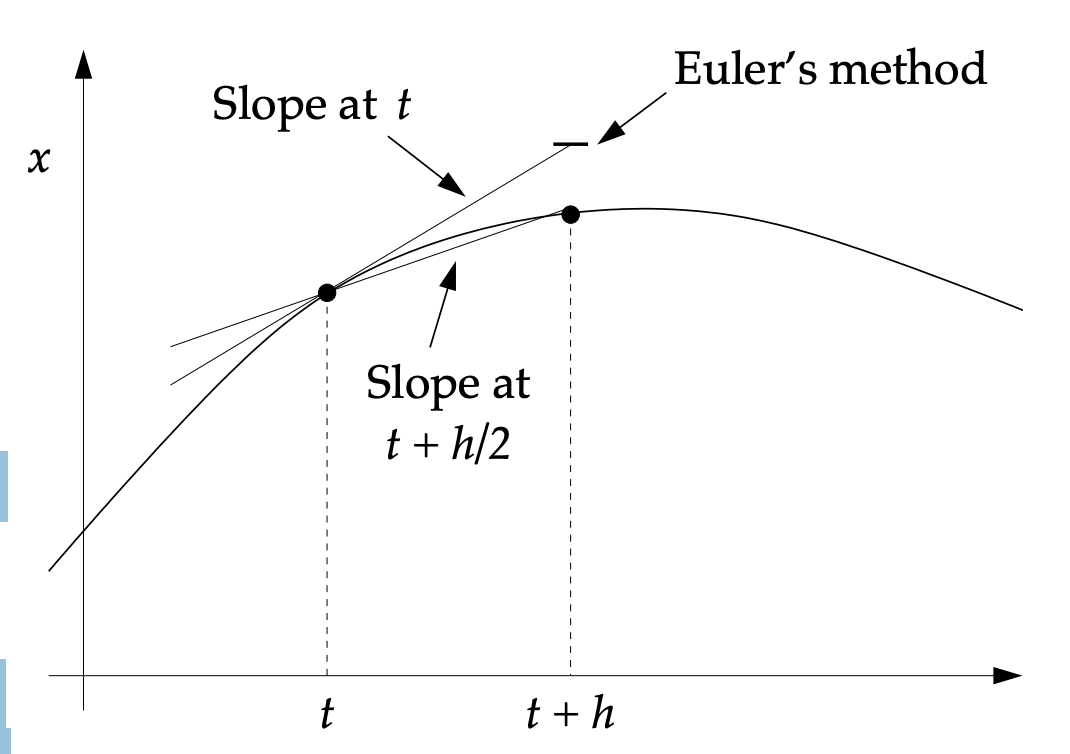

# SLIDES 8-->16

### Much easier to change name of derivatives!

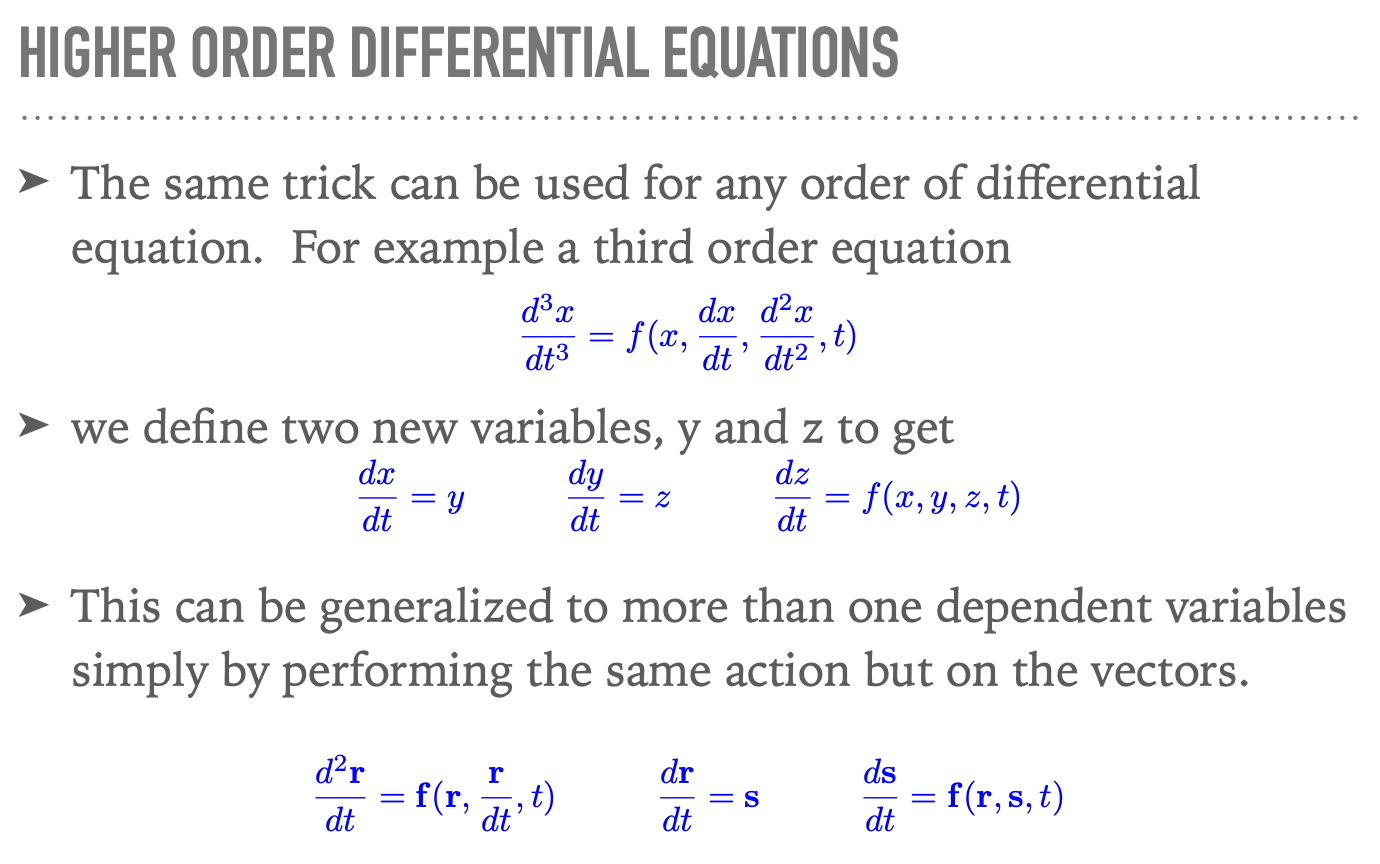

## Example 8.6 - THE NONLINEAR PENDULUM
*  Let’s consider the pendulum which we generally treat as
linear, but in reality in nonlinear. Say we have a pendulum
with a length l and a mass m at the end of it. The equation of
motion for the pendulum will be
*  a second order differential equation. Now let us use our trick
*  we now have two first-order equations. So lets combine them
into vectors, r=(θ,ω). The f will be the vector function that
acts on them.


## Exercise 8.4

In [1]:
"""
Write a program to solve the two first-order equations, using the fourth-order Runge--Kutta method for a pendulum with a 10 cm arm. Use your program to calculate the angle θ of displacement for several periods of the pendulum when it is released from a standstill at θ =179° from the vertical. Make a graph of θ as a function of time
"""




# we can code up f as the following

def f(r,t):
    theta=r[0]
    omega=r[1]
    ftheta = omega
    fomega = -(g/l)*sin(theta)
    return np.array([ftheta,fomega],float)




# to make it 4th order Runge-Kutta, we do (for some h):

h = 1
k1 = h*f(x,t)
k2 = h*f(x+0.5*k1,t+0.5*h)
k3 = h*f(x+0.5*k2,t+0.5*h)
k4 = h*f(x+k3,t+h)
x += (k1+2*k2+2*k3+k4)/6



NameError: name 'x' is not defined

'\nh = l1 * np.cos(179) # in degrees\nk1 = h*f(x,t)\nk2 = h*f(x+0.5*k1,t+0.5*h)\nk3 = h*f(x+0.5*k2,t+0.5*h)\nk4 = h*f(x+k3,t+h)\nx += (k1+2*k2+2*k3+k4)/6\n'

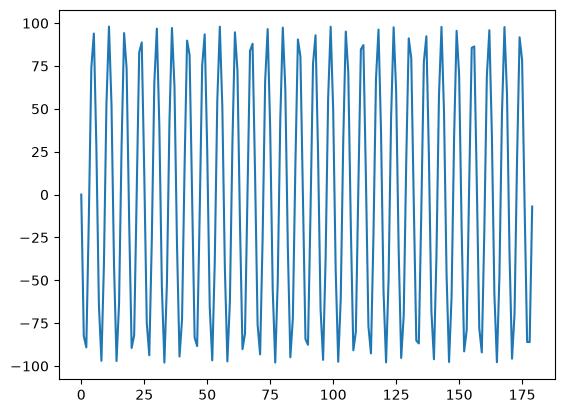

In [6]:
import numpy as np
from matplotlib import pyplot as plt

theta_pend_init = 179.0   # radians
g1 = 9.8
l1 = 0.1  # length of arm, m

def eqn(theta, g=g1, l = l1):
    theta_deriv = -(g/l) * np.sin(theta)
    return theta_deriv





theta_vals = np.arange(0,180,1)

d2x_dt2 = eqn(theta_vals)

plt.plot(theta_vals, d2x_dt2)



"""
h = l1 * np.cos(179) # in degrees
k1 = h*f(x,t)
k2 = h*f(x+0.5*k1,t+0.5*h)
k3 = h*f(x+0.5*k2,t+0.5*h)
k4 = h*f(x+k3,t+h)
x += (k1+2*k2+2*k3+k4)/6
"""




# 10/27/26

### Varying the Step Size
### (starting on page 23/69)

for now, we have been guessing h and having it be a constant value, which is not necessarily good/efficient for all functions.





# Adaptive Time Steps:
## very efficient use of computer capabilities. try to include this in final project!!

# OTHER METHODS (INSTEAD OF EULER'S AND RUNGE-KUTTA)
### * Leapfrog Method
### * Verlet Method
### * Modified Midpoint Method
### * Burlisch-Stoer Method

## LEAPFROG METHOD
* The leapfrog method is very similar to Runge-Kutta, but has certain advantages for certain problems.
* In Runge-Kutta we evaluate x half way to were we want and then use that to go the full step.


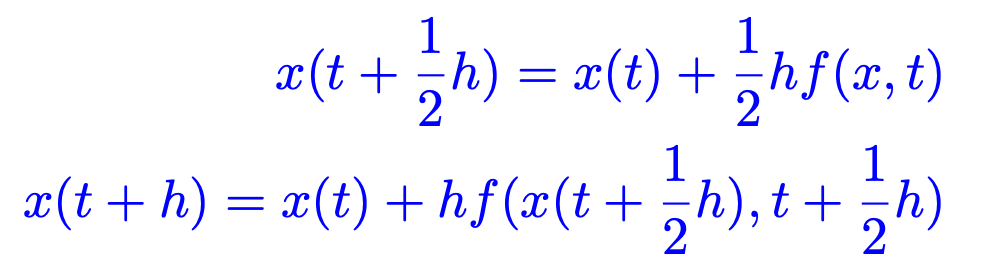
* The leapfrog method instead uses the previous half step to
calculate the next 3/2h step.

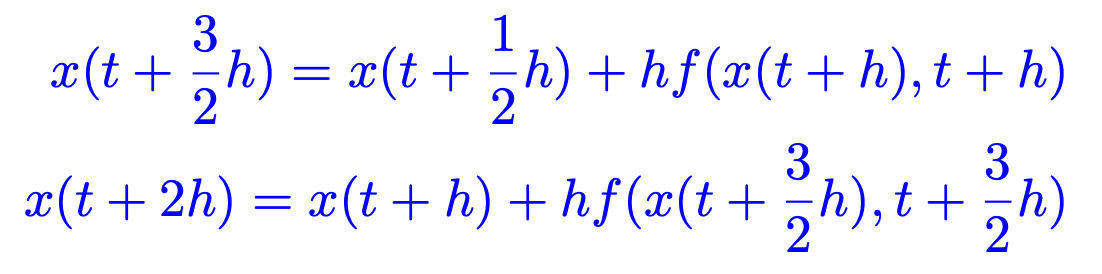



### VISUALIZED:
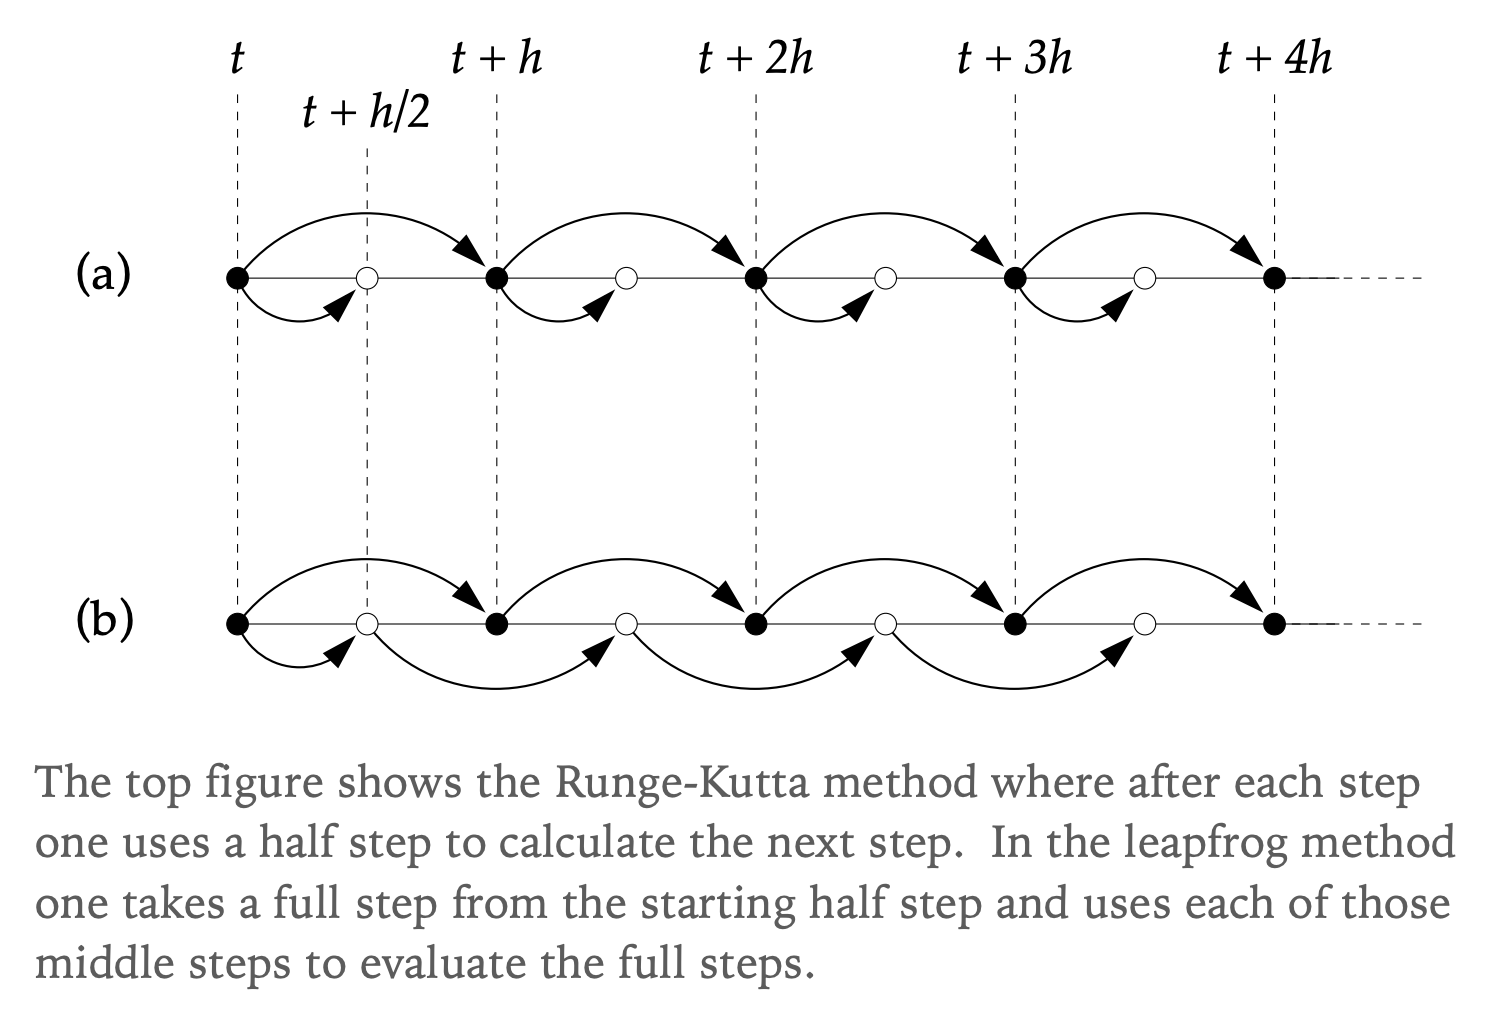


* This method can be extended to multiple variables and
functions just like Runge-Kutta and to higher order
derivatives. So the obvious question is what do we gain over
Runge-Kutta by using the leapfrog method.
* The leapfrog method has two significant features that make it
interesting:
    1. The method is **time-reversal symmetric**. This can be useful
for physics problems where energy conservation is
important.
    2. The error is even in step size h, which makes it an ideal
starting point for Richardson extrapolation.


### TIME REVERSAL SYMMETRY:
* The leapfrog method is time symmetric because if we started
at some point and evaluated forward in time to some t’ and
then applied the algorithm in reverse with step size -h we
would end up where we started (aside from rounding error)
* This is not true for 2nd order Runge-Kutta, if you perform the
algorithm in reverse each step with have errors of O(h3)
compared to what you got in the forward direction.
* Why is time reversal symmetry important, because if you
have a system that should conserve energy, numerical errors
will cause the energy to drift. But if your solver is time
symmetric, then the energy will be conserved
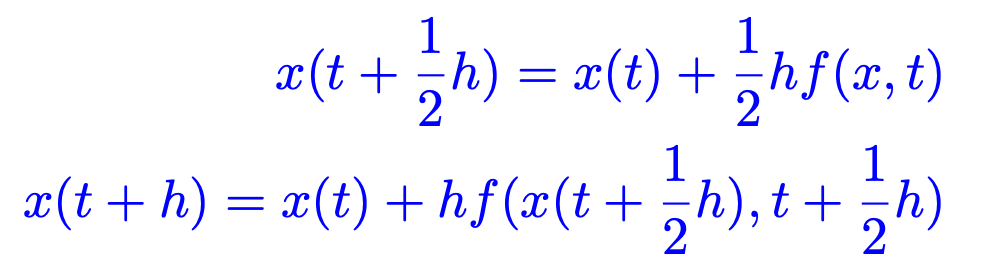

# VERLET METHOD


# only a valid option when one variable is defined as the derivative of the other variable ... works like leapfrog as well
--> calculate one variable on x and one on 3/2 x



## EXERCISE 8.12 -- ORBIT OF THE EARTH

* Use the Verlet method to calculate the
orbit of the Earth around the Sun. The
equations of motion for the position
r=(x,y) of the planet are the same as
those for any orbiting body. In vector
form they are [EQN] where G=6.6738E-11, M=1.9891E30 kg.
* The orbit of the Earth is not perfectly
circular. When it is at closet point it is
moving precisely tangentially at a
distance of 1.4710E11 m with a velocity
of 3.0287E4 m/s.
* Write a program to calculate the orbit of
the Earth using the Verlet method with a
time step of h=1 hour. Make a plot of the
orbit for several complete revolutions.

In [7]:
# assuming we start from the position where the earth is directly to the rght of the Sun at R = R


G = 6.6738e-11
M = 1.9891e30  # kg
R = 1.4710e11  # m

num_steps = 24 * 365  # number hours in a year
h = 1  # hour



def f(x,y,v_x,v_y):
    dx_dt = v_x
    dy_dt = v_y
    a_x = -G*M*x / (x**2 + y**2)**(3/2)
    a_y = -G*M*y / (x**2 + y**2)**(3/2)
    return dx_dt, dy_dt, a_x, a_y

x_init = R
y_init = 0
# r_init = (x,y)
vx_init = 0
vy_init = 3.0287e4  # m/s, upward then CCW



for some_steps in theta ...:
    h = R * np.cos(0) # in degrees
    k1 = h*f(x,t)
    k2 = h*f(x+0.5*k1,t+0.5*h)
    k3 = h*f(x+0.5*k2,t+0.5*h)
    k4 = h*f(x+k3,t+h)
    x += (k1+2*k2+2*k3+k4)/6





r(t+h)= r(t)+ hv(t + 0.5*h)
k = h*f(r(t + h),t + h)
v(t + h)= v(t + 0.5*h)+ 0.5*k
v(t + 1.5*h)= v(t + 0.5*h)+ k
